# Prédiction de la résistance aux antibiotiques
Ce notebook suit un entonnoir en deux temps :

1. **choisir** les antibiotiques exploitables (couverture, prévalence, critères strict/élargi) ;
2. **explorer en détail** un antibiotique choisi (régression logistique, RandomForest, XGBoost, MLP, SHAP) ;


## 1. Imports et configuration

In [23]:
from pathlib import Path
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import copy
import shap
import torch
from matplotlib.patches import Patch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# évite les conflits de threads entre torch et les librairies natives
torch.set_num_threads(1)

# on défini la graine 
SEED = 42

# on change les paramètres de sortie graphiques 
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

## 2. Chargement des splits

Le chemin est résolu de façon à fonctionner que le notebook soit lancé depuis `notebooks/` ou depuis la racine du dépôt.

In [13]:
def find_splits_dir() -> Path:
    candidates = [
        Path("../data/splits_all_snp_3way"),
        Path("data/splits_all_snp_3way"),
    ]
    for candidate in candidates:
        if (candidate / "X_train.parquet").exists():
            return candidate.resolve()
    raise FileNotFoundError(
        "Impossible de trouver data/splits_all_snp_3way. "
        "Lance le notebook depuis la racine du dépôt ou depuis notebooks/."
    )

DATA = find_splits_dir()
REPO_ROOT = DATA.parent.parent
sys.path.insert(0, str(REPO_ROOT))

MODEL_DIR = REPO_ROOT / "models" / "by_atb"
REPORT_DIR = REPO_ROOT / "reports"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA       :", DATA)
print("REPO_ROOT  :", REPO_ROOT)
print("MODEL_DIR  :", MODEL_DIR)
print("REPORT_DIR :", REPORT_DIR)

DATA       : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL/data/splits_all_snp_3way
REPO_ROOT  : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL
MODEL_DIR  : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL/models/by_atb
REPORT_DIR : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL/reports


In [14]:
SPLITS = ("train", "val", "test")
data = {}

for split in SPLITS:
    data[f"X_{split}"] = pd.read_parquet(DATA / f"X_{split}.parquet")
    data[f"Y_{split}"] = pd.read_parquet(DATA / f"Y_{split}.parquet")
    if not data[f"X_{split}"].index.equals(data[f"Y_{split}"].index):
        raise ValueError(f"Index désalignés pour le split {split}")

n_features = data["X_train"].shape[1]
n_drugs = data["Y_train"].shape[1]
n_total = sum(len(data[f"X_{split}"]) for split in SPLITS)

print(f"{n_total:,} génomes au total | {n_features:,} features | {n_drugs} antibiotiques")
for split in SPLITS:
    print(
        f"{split:5s} : X={data[f'X_{split}'].shape} "
        f"| Y={data[f'Y_{split}'].shape} "
        f"| dtype X={data[f'X_{split}'].dtypes.iloc[0]}"
    )

6,949 génomes au total | 34,744 features | 48 antibiotiques
train : X=(4722, 34744) | Y=(4722, 48) | dtype X=uint8
val   : X=(1110, 34744) | Y=(1110, 48) | dtype X=uint8
test  : X=(1117, 34744) | Y=(1117, 48) | dtype X=uint8


## 3. Couverture du phénotype par antibiotique

Avant d'entraîner quoi que ce soit, on vérifie combien d'individus sont testés et quelle est la prévalence de la résistance sur chaque split.

In [15]:
def coverage_table(data: dict) -> pd.DataFrame:
    rows = []
    for atb in data["Y_train"].columns:
        row = {"atb": atb}
        for split in SPLITS:
            y = data[f"Y_{split}"][atb]
            n = int(y.notna().sum())
            n_r = int((y == 1).sum())
            row[f"n_{split}"] = n
            row[f"pct_R_{split}"] = round(100 * n_r / n, 1) if n else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("atb")


coverage = coverage_table(data)
coverage["n_min"] = coverage[[f"n_{split}" for split in SPLITS]].min(axis=1)
coverage = coverage.sort_values("n_test", ascending=False)
coverage.to_csv(REPORT_DIR / "coverage_by_atb.csv")
coverage

,n_train,pct_R_train,n_val,pct_R_val,n_test,pct_R_test,n_min
atb,,,,,,,
ciprofloxacin,4050,23.5,946,17.9,939,17.6,939
gentamicin,4042,10.3,935,9.4,933,9.1,933
ceftazidime,3881,10.2,943,7.5,921,9.6,921
piperacillin/tazobactam,3823,4.3,902,5.7,892,3.6,892
cefotaxime,3654,16.7,862,8.9,852,11.5,852
ampicillin,3245,51.1,822,48.2,784,47.8,784
meropenem,3233,0.4,680,0.7,721,0.6,680
cefuroxime,2676,14.3,769,11.6,656,11.0,656
amoxicillin/clavulanic acid,2542,29.7,560,31.1,608,31.1,560


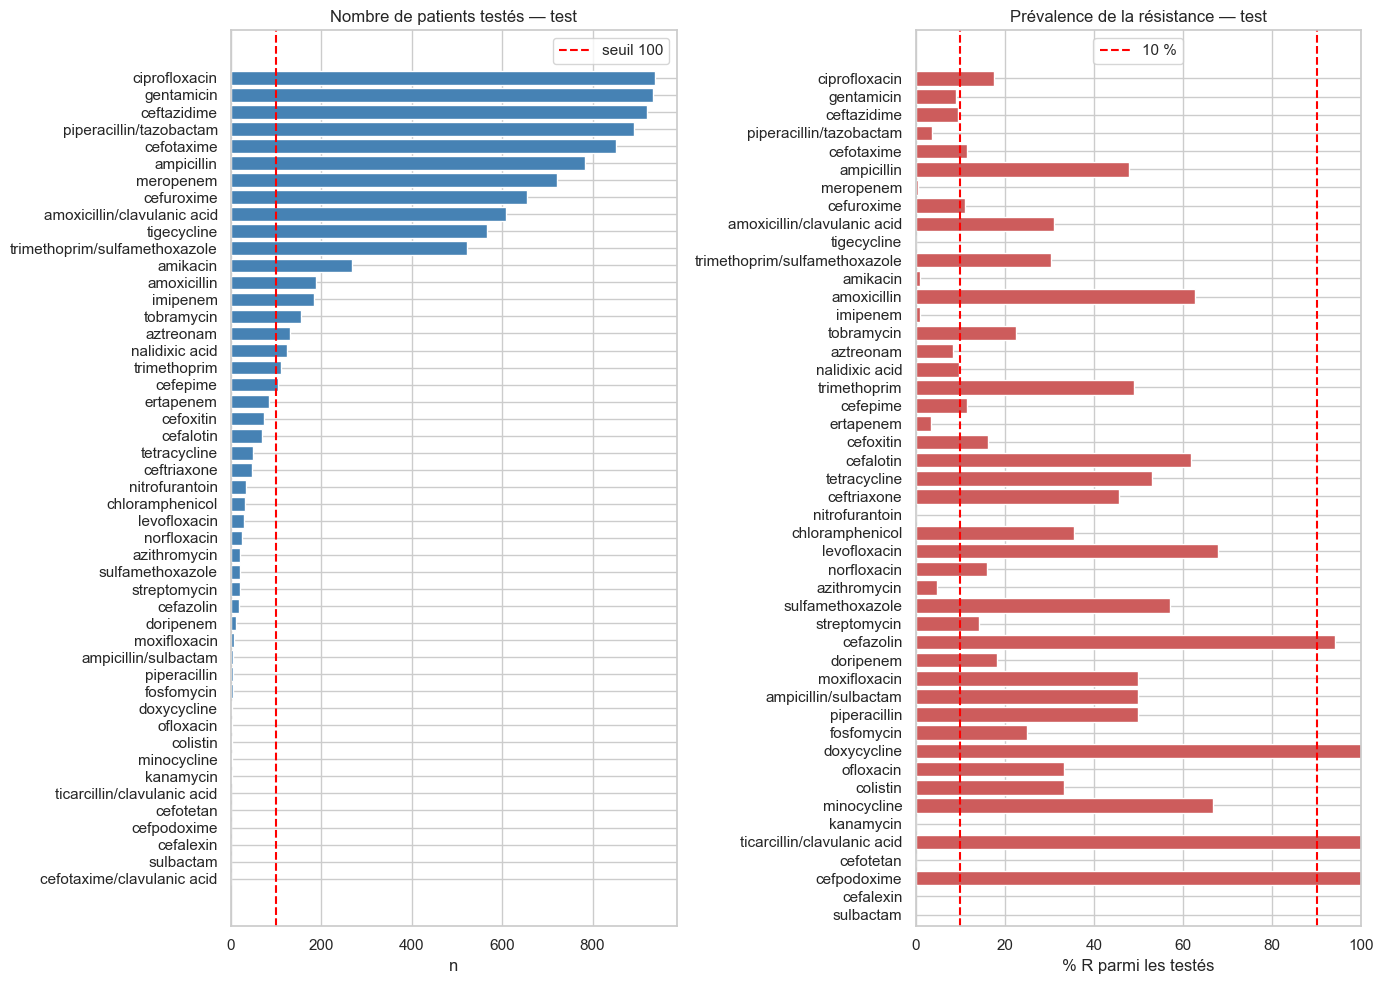

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 10))

order = coverage.sort_values("n_test")

axes[0].barh(order.index, order["n_test"], color="steelblue")
axes[0].axvline(100, color="red", linestyle="--", label="seuil 100")
axes[0].set_title("Nombre de patients testés — test")
axes[0].set_xlabel("n")
axes[0].legend()

axes[1].barh(order.index, order["pct_R_test"], color="indianred")
axes[1].axvline(10, color="red", linestyle="--", label="10 %")
axes[1].axvline(90, color="red", linestyle="--")
axes[1].set_xlim(0, 100)
axes[1].set_title("Prévalence de la résistance — test")
axes[1].set_xlabel("% R parmi les testés")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Quels antibiotiques sont exploitables ?

Deux critères sont calculés :

- **strict** : au moins 100 individus testés et au moins 10 % de classe minoritaire sur chacun des trois splits ;
- **élargi** : au moins 100 individus testés et au moins 5 % de classe minoritaire.

Le seuil de 100 est un paramètre du pipeline (`min_samples`) ; on peut le monter à 300 pour ne garder que les antibiotiques les plus solides.

In [17]:
MIN_SAMPLES = 100


def is_eligible(row, min_minority_pct: float) -> bool:
    '''Vrai si le split est assez grand et assez équilibré sur les 3 splits.'''
    for split in SPLITS:
        n = row[f"n_{split}"]
        pct = row[f"pct_R_{split}"]
        if n < MIN_SAMPLES or not (0 < pct < 100):
            return False
        if min(pct, 100 - pct) < min_minority_pct:
            return False
    return True


coverage["eligible_10"] = coverage.apply(is_eligible, axis=1, min_minority_pct=10.0)
coverage["eligible_5"] = coverage.apply(is_eligible, axis=1, min_minority_pct=5.0)

# Listes dérivées des critères : plus besoin de recopier les noms à la main.
CANDIDATS_STRICT = coverage.index[coverage["eligible_10"]].tolist()
CANDIDATS_LARGE = coverage.index[coverage["eligible_5"]].tolist()

print(
    f"strict (>= {MIN_SAMPLES} testés et >= 10 % minoritaire) : "
    f"{len(CANDIDATS_STRICT)} antibiotiques"
)
print("  ", CANDIDATS_STRICT)
print()
print(
    f"élargi (>= {MIN_SAMPLES} testés et >= 5 % minoritaire) : "
    f"{len(CANDIDATS_LARGE)} antibiotiques"
)
print("  ", CANDIDATS_LARGE)

coverage.to_csv(REPORT_DIR / "coverage_by_atb.csv")
coverage.head()


strict (>= 100 testés et >= 10 % minoritaire) : 9 antibiotiques
   ['ciprofloxacin', 'ampicillin', 'cefuroxime', 'amoxicillin/clavulanic acid', 'trimethoprim/sulfamethoxazole', 'amoxicillin', 'tobramycin', 'trimethoprim', 'cefepime']

élargi (>= 100 testés et >= 5 % minoritaire) : 14 antibiotiques
   ['ciprofloxacin', 'gentamicin', 'ceftazidime', 'cefotaxime', 'ampicillin', 'cefuroxime', 'amoxicillin/clavulanic acid', 'trimethoprim/sulfamethoxazole', 'amoxicillin', 'tobramycin', 'aztreonam', 'nalidixic acid', 'trimethoprim', 'cefepime']


,n_train,pct_R_train,n_val,pct_R_val,n_test,pct_R_test,n_min,eligible_10,eligible_5
atb,,,,,,,,,
ciprofloxacin,4050,23.5,946,17.9,939,17.6,939,True,True
gentamicin,4042,10.3,935,9.4,933,9.1,933,False,True
ceftazidime,3881,10.2,943,7.5,921,9.6,921,False,True
piperacillin/tazobactam,3823,4.3,902,5.7,892,3.6,892,False,False
cefotaxime,3654,16.7,862,8.9,852,11.5,852,False,True


## 5. Candidats retenus

La liste des ATB à traiter est **dérivée** des critères de la section 4, plus tapée à la main :

- `CANDIDATS_STRICT` : les ATB qui respectent le critère strict ;
- `CANDIDATS_LARGE` : ceux qui respectent le critère élargi.

Par défaut, `ATB_CIBLES = CANDIDATS_LARGE` pour la boucle de la section 9. Un sous-ensemble manuel — les 5 stricts + `gentamicin`, `ceftazidime`, `cefotaxime` — est proposé en commentaire pour reproduire les rapports.


In [19]:
# Candidats calculés à la section 4 :
#   CANDIDATS_STRICT : critère strict  (>= 10 % de classe minoritaire)
#   CANDIDATS_LARGE  : critère élargi  (>= 5 % de classe minoritaire)
#
# Par défaut : tous les candidats élargis.
ATB_CIBLES = CANDIDATS_STRICT

# Sous-ensemble manuel utilisé dans les rapports (5 stricts + 3 ATB utiles) :
# ATB_CIBLES = [
#     "ciprofloxacin",
#     "ampicillin",
#     "cefuroxime",
#     "amoxicillin/clavulanic acid",
#     "trimethoprim/sulfamethoxazole",
#     "gentamicin",
#     "ceftazidime",
#     "cefotaxime",
# ]

missing = [atb for atb in ATB_CIBLES if atb not in data["Y_train"].columns]
assert not missing, f"ATB absents des colonnes de Y : {missing}"

print(f"{len(ATB_CIBLES)} ATB ciblés sur {len(CANDIDATS_LARGE)} candidats élargis")
ATB_CIBLES


9 ATB ciblés sur 14 candidats élargis


['ciprofloxacin',
 'ampicillin',
 'cefuroxime',
 'amoxicillin/clavulanic acid',
 'trimethoprim/sulfamethoxazole',
 'amoxicillin',
 'tobramycin',
 'trimethoprim',
 'cefepime']

## 6. Sélection de l'antibiotique à explorer

`pick_antibiotic` prépare les splits de l'ATB choisi et les expose dans les variables globales `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test` : les cellules de la section 7 n'ont donc pas besoin de connaître son nom.

La fonction vérifie aussi que l'ATB fait partie de `CANDIDATS_LARGE` et prévient sinon. Pour changer d'antibiotique, il suffit de modifier `ATB` ci-dessous.


In [22]:
# ============================================================
#  SÉLECTION DE L'ANTIBIOTIQUE À EXPLORER
# ============================================================
from src.pipeline import prepare_data_for_atb

# définition de l'antiobiotique explorer
ATB = "cefuroxime"  

# on prépare les splits train, val et test pour l'ATP choisi
def pick_antibiotic(atb: str, verbose: bool = True) -> dict:
    
    global X_train, y_train, X_val, y_val, X_test, y_test, splits_atb

    available = data["Y_train"].columns.tolist()
    if atb not in available:
        raise KeyError(
            f"{atb!r} n'est pas un antibiotique du jeu de données. "
            f"Choix possibles ({len(available)}) : {available}"
        )

    if atb not in CANDIDATS_LARGE:
        print(
            f"⚠️  {atb!r} ne respecte pas le critère de sélection"
            f"(>= {MIN_SAMPLES} testés et >= 5 % de classe minoritaire).\n"
            f"    Candidats : {CANDIDATS_LARGE}"
        )

    splits_atb = prepare_data_for_atb(atb, data)

    X_train, y_train = splits_atb["train"]
    X_val, y_val = splits_atb["val"]
    X_test, y_test = splits_atb["test"]

    if verbose:
        row = coverage.loc[atb]
        print(f"Antibiotique  : {atb}")
        print(
            f"n testés      : {row['n_train']:.0f} / {row['n_val']:.0f} / "
            f"{row['n_test']:.0f}  (train / val / test)"
        )
        print(
            "prévalence R  : "
            f"{y_train.mean():.1%} / {y_val.mean():.1%} / {y_test.mean():.1%} "
            "(train / val / test)"
        )
        print(f"features      : {X_train.shape[1]:,}")

    return splits_atb


splits_atb = pick_antibiotic(ATB)


Antibiotique  : cefuroxime
n testés      : 2676 / 769 / 656  (train / val / test)
prévalence R  : 14.3% / 11.6% / 11.0% (train / val / test)
features      : 34,744


## 7. Exploration détaillée de l'antibiotique choisi

Nous allons reprendre la démarche détaillée de `exploration_benjamin.ipynb` pour l'ATB sélectionné en section 6 :

- régression logistique classique et pénalisée L1 (sélection de variables) ;
- RandomForest et XGBoost ;
- comparaison des modèles, choix du seuil sur la validation, calibration ;
- évaluation sur le test, SHAP et analyse d'erreurs ;
- MLP PyTorch, sans puis avec sélection de variables.

Toutes les cellules s'adaptent automatiquement à `ATB`.


### 7.1 Imports et fonction d'évaluation

In [25]:
# on défini on fonction qui choisi le seuil maximisant le score F1 sur le jeu de données de validation
def best_f1_threshold(model, X, y) -> float:
    proba = model.predict_proba(X)[:, 1]
    prec, rec, thr = precision_recall_curve(y, proba)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
    return float(thr[np.argmax(f1[:-1])])

# on défini une fonction d'évaluation d'un modèle
def evaluate(name, model, X, y, threshold: float = 0.5) -> dict:
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y, pred),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
    }

    print(f"\n=== {name} (seuil = {threshold:.3f}) ===")
    print(f"Accuracy          : {metrics['accuracy']:.3f}")
    print(f"Balanced accuracy : {metrics['balanced_acc']:.3f}")
    print(f"Precision         : {metrics['precision']:.3f}")
    print(f"Recall            : {metrics['recall']:.3f}")
    print(f"F1                : {metrics['f1']:.3f}")
    print(f"ROC-AUC           : {metrics['roc_auc']:.3f}")
    print(f"PR-AUC            : {metrics['pr_auc']:.3f}")
    print(pd.DataFrame(
        confusion_matrix(y, pred),
        index=["Observé 0", "Observé 1"],
        columns=["Prédit 0", "Prédit 1"],
    ))

    return metrics


### 7.2 Régression logistique

#### 7.2.1 Régression logistique classique

In [26]:
# on défini le modèle 
model_lr = LogisticRegression(random_state=SEED, max_iter=2000)

# on entraîne le modèle
model_lr.fit(X_train, y_train)

# on évalue le modèle
res_lr = evaluate("Régression logistique — validation", model_lr, X_val, y_val)



=== Régression logistique — validation (seuil = 0.500) ===
Accuracy          : 0.919
Balanced accuracy : 0.710
Precision         : 0.765
Recall            : 0.438
F1                : 0.557
ROC-AUC           : 0.753
PR-AUC            : 0.593
           Prédit 0  Prédit 1
Observé 0       668        12
Observé 1        50        39


#### 7.2.2 Régression logistique pénalisée L1 (LASSO)

On balaie plusieurs valeurs de l'hyperparamètre `C` et on garde celle qui maximise la PR-AUC de validation.


In [ ]:
C_values = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]

models_l1 = {}
rows_l1 = []

for C in C_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            l1_ratio=1.0,
            solver="liblinear",
            C=C,
            max_iter=5000,
            random_state=SEED,
        )),
    ])
    pipe.fit(X_train, y_train)
    m = evaluate(f"LR-L1 C={C}", pipe, X_val, y_val)
    m["C"] = C
    m["n_features"] = int((pipe.named_steps["clf"].coef_.ravel() != 0).sum())
    models_l1[C] = pipe
    rows_l1.append(m)

comparison_l1 = pd.DataFrame(rows_l1).set_index("model")

# C retenu : celui qui maximise la PR-AUC de validation
best_C = comparison_l1.loc[comparison_l1["pr_auc"].idxmax(), "C"]
print(f"C retenu (PR-AUC max) : {best_C}")

best_pipe = models_l1[best_C]
coefs = best_pipe.named_steps["clf"].coef_.ravel()

selected = pd.DataFrame({
    "feature": X_train.columns,
    "coef": coefs,
    "abs_coef": np.abs(coefs),
})
selected = (selected[selected["coef"] != 0]
            .sort_values("abs_coef", ascending=False)
            .reset_index(drop=True))

print(f"{len(selected)} features sélectionnées sur {len(coefs)} "
      f"({100 * len(selected) / len(coefs):.2f}%)")
selected.head(30)



=== LR-L1 C=0.001 (seuil = 0.500) ===
Accuracy          : 0.116
Balanced accuracy : 0.500
Precision         : 0.116
Recall            : 1.000
F1                : 0.207
ROC-AUC           : 0.500
PR-AUC            : 0.116
           Prédit 0  Prédit 1
Observé 0         0       680
Observé 1         0        89

=== LR-L1 C=0.005 (seuil = 0.500) ===
Accuracy          : 0.887
Balanced accuracy : 0.511
Precision         : 1.000
Recall            : 0.022
F1                : 0.044
ROC-AUC           : 0.824
PR-AUC            : 0.593
           Prédit 0  Prédit 1
Observé 0       680         0
Observé 1        87         2

=== LR-L1 C=0.01 (seuil = 0.500) ===
Accuracy          : 0.922
Balanced accuracy : 0.673
Precision         : 0.939
Recall            : 0.348
F1                : 0.508
ROC-AUC           : 0.849
PR-AUC            : 0.662
           Prédit 0  Prédit 1
Observé 0       678         2
Observé 1        58        31

=== LR-L1 C=0.05 (seuil = 0.500) ===
Accuracy          : 0.922
Bala

KeyboardInterrupt: 

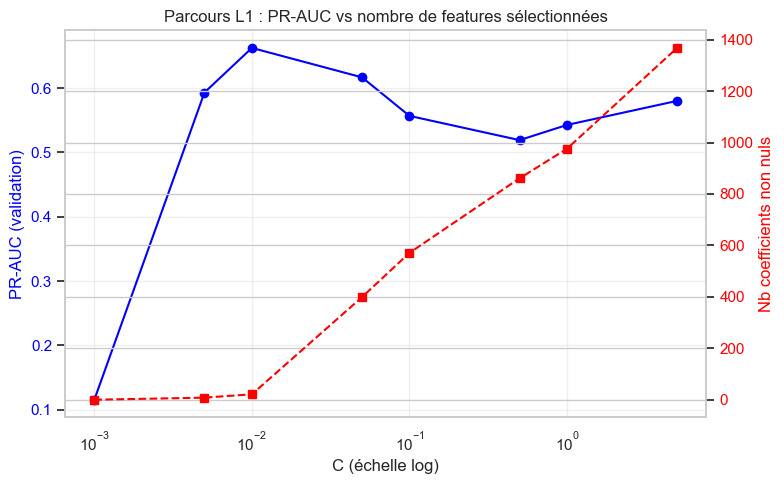

In [36]:
# on trace l'évolution de la PR-AUC en fonction de -log(C)
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(C_values, comparison_l1["pr_auc"], "o-", color="blue", label="PR-AUC")
ax1.set_xscale("log")
ax1.set_xlabel("C (échelle log)")
ax1.set_ylabel("PR-AUC (validation)", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(C_values, comparison_l1["n_features"], "s--", color="red",
         label="Nb features non nulles")
ax2.set_ylabel("Nb coefficients non nuls", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Parcours L1 : PR-AUC vs nombre de features sélectionnées")
plt.tight_layout()
plt.show()


/var/folders/dq/xz942xqn5r54jy9b70nyd5980000gn/T/ipykernel_47329/3700935267.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


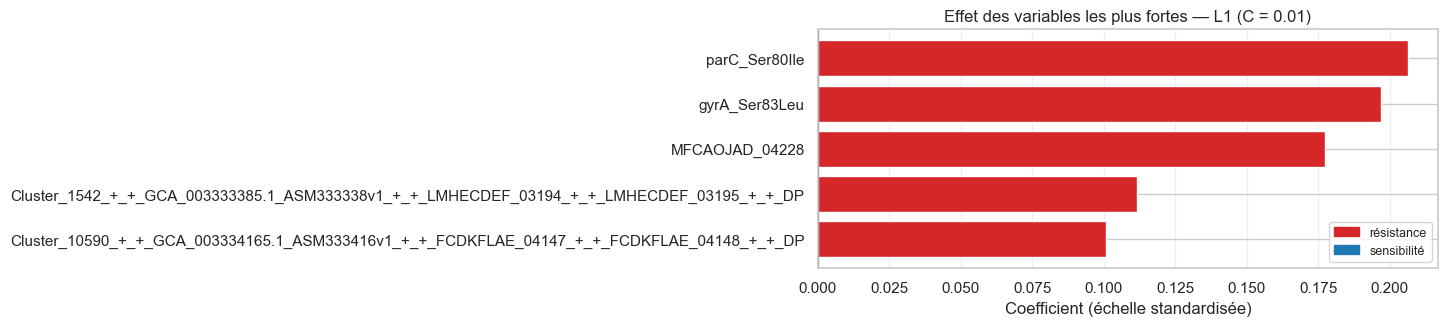

In [37]:
top_n = 5

if selected.empty:
    print("Aucune variable sélectionnée par la pénalisation L1.")
else:
    top = selected.head(top_n).iloc[::-1]

    fig, ax = plt.subplots(figsize=(8, 0.32 * len(top) + 1.5))
    colors = ["#d62728" if v > 0 else "#1f77b4" for v in top["coef"]]
    ax.barh(top["feature"], top["coef"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Coefficient (échelle standardisée)")
    ax.set_title(f"Effet des variables les plus fortes — L1 (C = {best_C})")
    ax.legend(handles=[
        Patch(color="#d62728", label="résistance"),
        Patch(color="#1f77b4", label="sensibilité"),
    ], loc="lower right", fontsize=9)
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


### 7.3 RandomForest

In [38]:
model_rf = RandomForestClassifier(random_state=SEED, n_jobs=-1)
model_rf.fit(X_train, y_train)
res_rf = evaluate("RandomForest — validation", model_rf, X_val, y_val)



=== RandomForest — validation (seuil = 0.500) ===
Accuracy          : 0.915
Balanced accuracy : 0.649
Precision         : 0.900
Recall            : 0.303
F1                : 0.454
ROC-AUC           : 0.827
PR-AUC            : 0.645
           Prédit 0  Prédit 1
Observé 0       677         3
Observé 1        62        27


### 7.4 XGBoost

In [31]:
model_xgb = XGBClassifier(random_state=SEED)
model_xgb.fit(X_train, y_train)

res_xgb = evaluate("XGBoost — validation", model_xgb, X_val, y_val)



=== XGBoost — validation (seuil = 0.500) ===
Accuracy          : 0.935
Balanced accuracy : 0.739
Precision         : 0.915
Recall            : 0.483
F1                : 0.632
ROC-AUC           : 0.831
PR-AUC            : 0.688
           Prédit 0  Prédit 1
Observé 0       676         4
Observé 1        46        43


### 7.5 Comparaison des modèles

In [ ]:
rows = []
rows.append(evaluate("LogReg", model_lr, X_val, y_val))
rows.append(evaluate("RF", model_rf, X_val, y_val))
rows.append(evaluate("XGB", model_xgb, X_val, y_val))
rows.append(evaluate("LogReg - L1", model_lrL1_best_C, X_val, y_val))

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)



=== LogReg (seuil = 0.500) ===
Accuracy          : 0.919
Balanced accuracy : 0.710
Precision         : 0.765
Recall            : 0.438
F1                : 0.557
ROC-AUC           : 0.753
PR-AUC            : 0.593
           Prédit 0  Prédit 1
Observé 0       668        12
Observé 1        50        39

=== RF (seuil = 0.500) ===
Accuracy          : 0.915
Balanced accuracy : 0.649
Precision         : 0.900
Recall            : 0.303
F1                : 0.454
ROC-AUC           : 0.827
PR-AUC            : 0.645
           Prédit 0  Prédit 1
Observé 0       677         3
Observé 1        62        27

=== XGB (seuil = 0.500) ===
Accuracy          : 0.935
Balanced accuracy : 0.739
Precision         : 0.915
Recall            : 0.483
F1                : 0.632
ROC-AUC           : 0.831
PR-AUC            : 0.688
           Prédit 0  Prédit 1
Observé 0       676         4
Observé 1        46        43

=== LogReg - L1 (seuil = 0.500) ===
Accuracy          : 0.922
Balanced accuracy : 0.673
Precis

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
LogReg,0.9194,0.7103,0.7647,0.4382,0.5571,0.7535,0.5929
RF,0.9155,0.6495,0.9000,0.3034,0.4538,0.8266,0.6448
XGB,0.9350,0.7386,0.9149,0.4831,0.6324,0.8308,0.6883
LogReg - L1,0.9220,0.6727,0.9394,0.3483,0.5082,0.8488,0.6624


### 7.6 Choix du seuil sur la validation

Le seuil est choisi pour maximiser le F1 sur la **validation**, jamais sur le test.


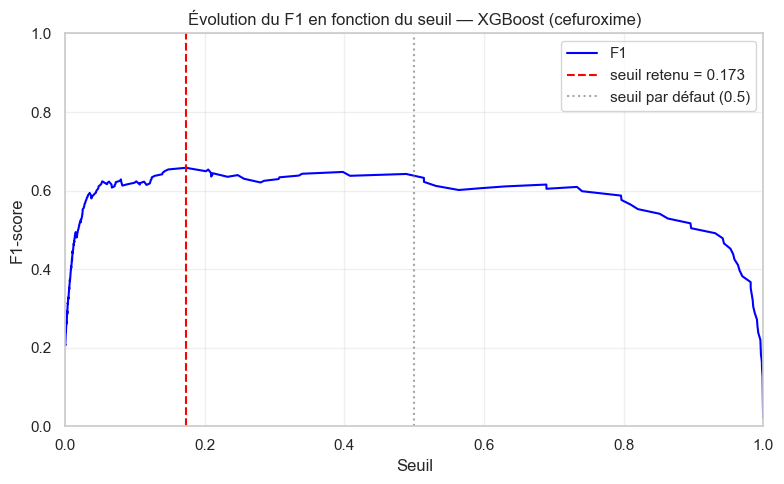

modèle retenu : XGB | seuil F1 max : 0.173


In [39]:
proba_val_xgb = model_xgb.predict_proba(X_val)[:, 1]

prec, rec, thr = precision_recall_curve(y_val, proba_val_xgb)
f1_curve = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
f1_plot = f1_curve[:-1]

best_thr = float(thr[np.argmax(f1_plot)])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thr, f1_plot, color="blue", label="F1")
ax.axvline(best_thr, color="red", linestyle="--",
           label=f"seuil retenu = {best_thr:.3f}")
ax.axvline(0.5, color="grey", linestyle=":", alpha=0.7,
           label="seuil par défaut (0.5)")
ax.set_xlabel("Seuil")
ax.set_ylabel("F1-score")
ax.set_title(f"Évolution du F1 en fonction du seuil — XGBoost ({ATB})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"modèle retenu : XGB | seuil F1 max : {best_thr:.3f}")


### 7.7 Courbe de calibration

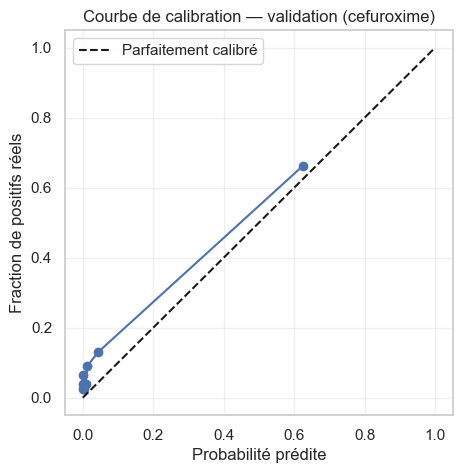

In [34]:
fig, ax = plt.subplots(figsize=(5, 5))

prob_true, prob_pred = calibration_curve(
    y_val, proba_val_xgb, n_bins=10, strategy="quantile"
)
ax.plot(prob_pred, prob_true, "o-")
ax.plot([0, 1], [0, 1], "k--", label="Parfaitement calibré")
ax.set_xlabel("Probabilité prédite")
ax.set_ylabel("Fraction de positifs réels")
ax.set_title(f"Courbe de calibration — validation ({ATB})")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


### 7.8 Évaluation sur le test

In [40]:
res_test = evaluate(
    "XGBoost — test", model_xgb, X_test, y_test, threshold=best_thr
)



=== XGBoost — test (seuil = 0.173) ===
Accuracy          : 0.927
Balanced accuracy : 0.758
Precision         : 0.722
Recall            : 0.542
F1                : 0.619
ROC-AUC           : 0.831
PR-AUC            : 0.665
           Prédit 0  Prédit 1
Observé 0       569        15
Observé 1        33        39


### 7.9 Interprétabilité

#### 7.9.1 SHAP

SHAP est calculé sur le jeu de **test**. Les valeurs sont des contributions en log-odds (marge du modèle), pas directement des probabilités.


Dimensions     : (656, 34744)
Valeur de base : -2.1856904


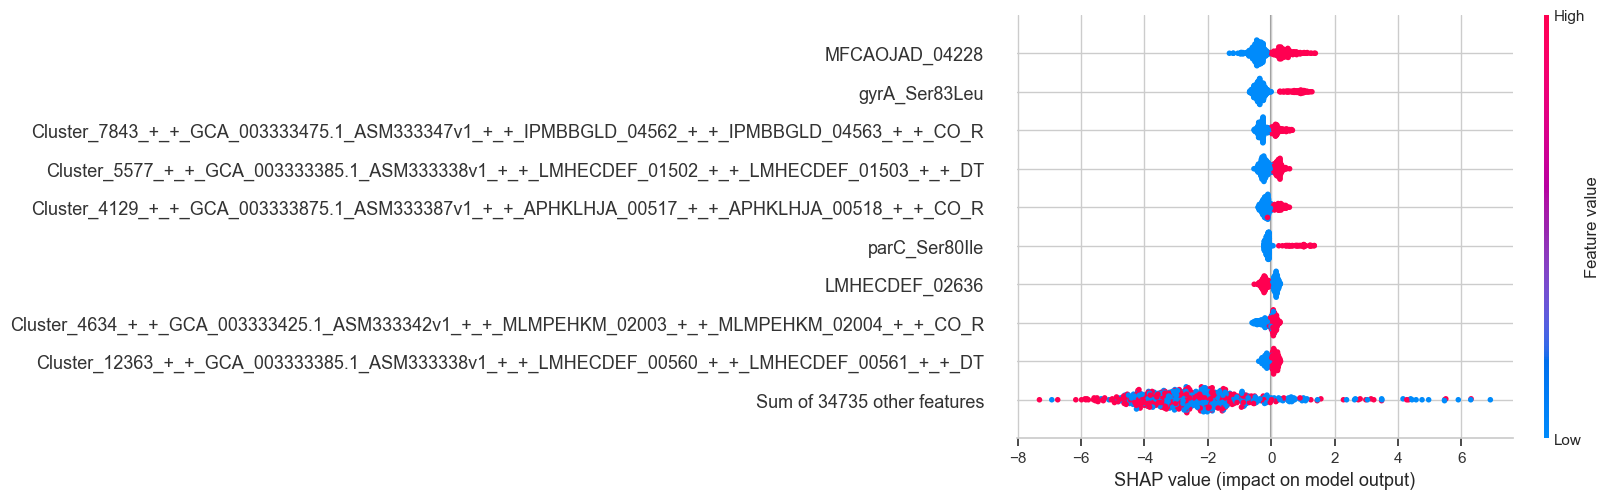

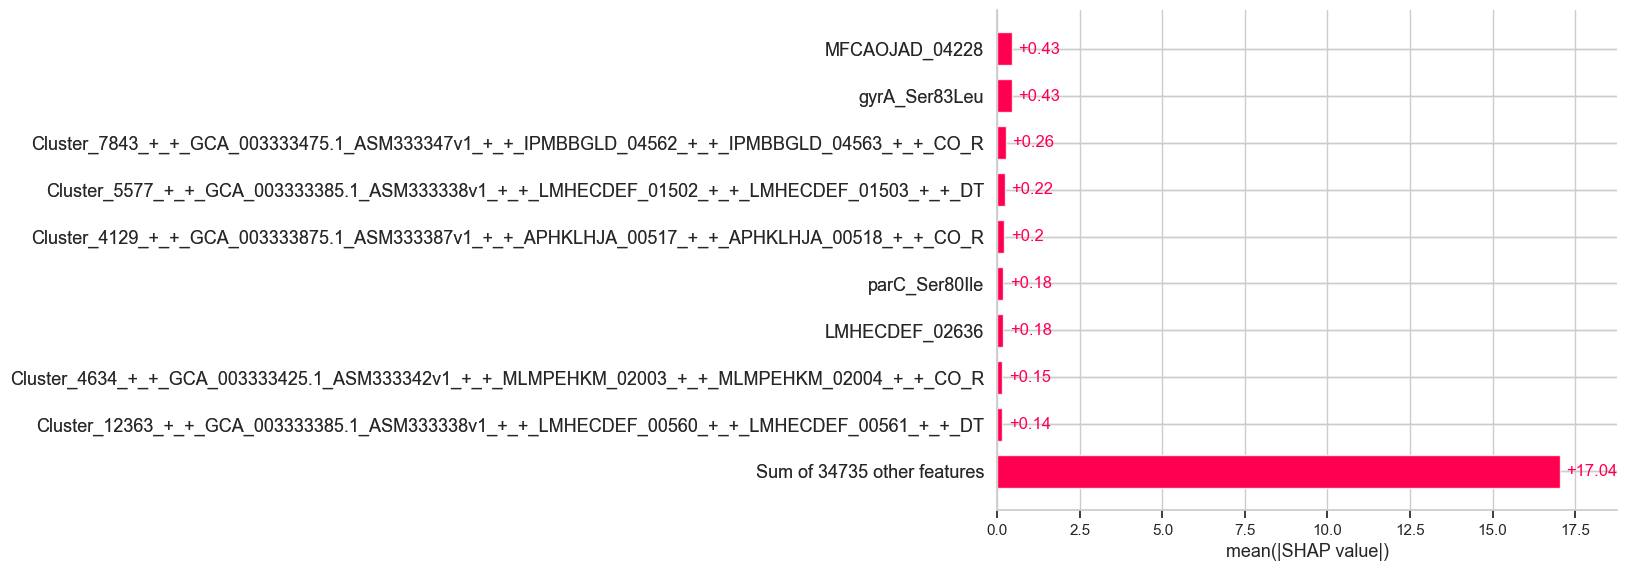

In [41]:
explainer_xgb = shap.TreeExplainer(model_xgb)
shap_value_xgb = explainer_xgb(X_test)

print("Dimensions     :", shap_value_xgb.values.shape)
print("Valeur de base :", shap_value_xgb.base_values[0])

# vue d'ensemble
shap.plots.beeswarm(shap_value_xgb, max_display=10)

# classement simple par importance moyenne
shap.plots.bar(shap_value_xgb, max_display=10)


#### 7.9.2 Analyse d'erreurs

On isole un faux positif et un faux négatif et on regarde, avec SHAP, quelles variables ont poussé la prédiction.


Nombre de Faux Positifs : 15
Nombre de Faux Négatifs : 33

=== Faux Positif (prédit résistant, réellement sensible) ===


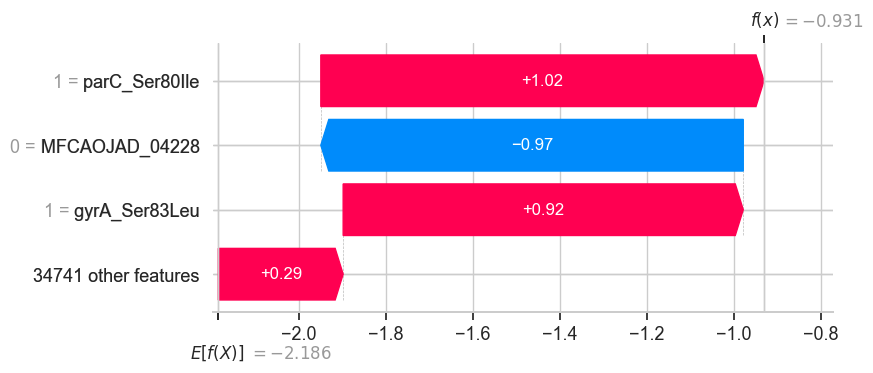


=== Faux Négatif (prédit sensible, réellement résistant) ===


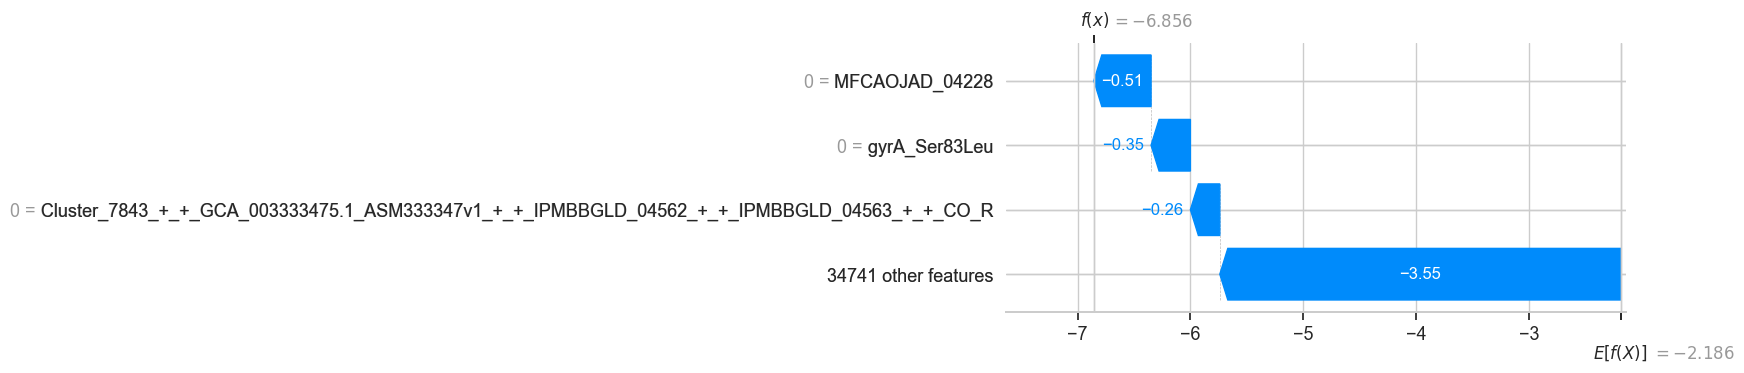

In [42]:
proba_test = model_xgb.predict_proba(X_test)[:, 1]
pred_test = proba_test >= best_thr
y_true = y_test.values

i_fp = np.where((y_true == 0) & pred_test)[0]
i_fn = np.where((y_true == 1) & ~pred_test)[0]

print(f"Nombre de Faux Positifs : {len(i_fp)}")
print(f"Nombre de Faux Négatifs : {len(i_fn)}")

if len(i_fp) > 0:
    print("\n=== Faux Positif (prédit résistant, réellement sensible) ===")
    shap.plots.waterfall(shap_value_xgb[i_fp[0]], max_display=4)

if len(i_fn) > 0:
    print("\n=== Faux Négatif (prédit sensible, réellement résistant) ===")
    shap.plots.waterfall(shap_value_xgb[i_fn[0]], max_display=4)


### 7.10 Deep learning : MLP PyTorch

Deux variantes, comme dans `exploration_benjamin.ipynb` :

1. **sans sélection de variables** : le MLP voit toutes les features (coûteux en mémoire) ;
2. **avec sélection de variables** : top 50 features par SHAP, bien plus rapide et souvent meilleur.


#### 7.10.1 Tenseurs et DataLoader

In [43]:
Xtrain = torch.tensor(X_train.to_numpy(dtype=np.float32))
Xval = torch.tensor(X_val.to_numpy(dtype=np.float32))
Xtest = torch.tensor(X_test.to_numpy(dtype=np.float32))

ytrain = torch.tensor(y_train.to_numpy(dtype=np.float32)).view(-1, 1)
y_val_tensor = torch.tensor(y_val.to_numpy(dtype=np.float32))

train_loader = DataLoader(
    TensorDataset(Xtrain, ytrain),
    batch_size=64,
    shuffle=True,
    num_workers=0,
)

print(Xtrain.shape, ytrain.shape)


torch.Size([2676, 34744]) torch.Size([2676, 1])


#### 7.10.2 Configuration du modèle

In [44]:
# pondération pour le déséquilibre des classes
nb_pos = (y_train == 1).sum()
nb_neg = (y_train == 0).sum()
pos_weight = torch.tensor([nb_neg / nb_pos], dtype=torch.float32)
print(f"pos_weight = {pos_weight.item():.3f}")

# architecture à deux couches cachées
mlp = nn.Sequential(
    nn.Linear(Xtrain.shape[1], 512),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
)

criterion_eval = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(mlp.parameters(), lr=0.001, weight_decay=1e-4)


pos_weight = 6.005


#### 7.10.3 Entraînement (early stopping sur la PR-AUC de validation)

La boucle d'entraînement est factorisée dans `train_mlp` : elle sert aux deux variantes du MLP.


Early stopping epoch 16 — best val PR-AUC 0.675
meilleur epoch = 1 | best val PR-AUC = 0.675


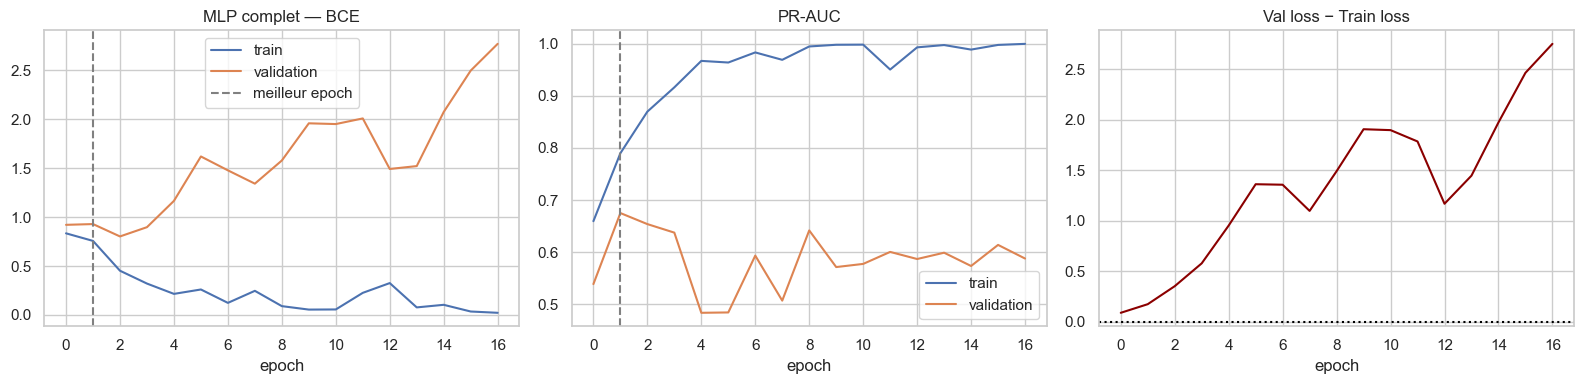

In [45]:
def train_mlp(mlp, loader, criterion, optimizer, Xtr, Xva, ytr, yva,
              max_epochs: int = 200, patience_max: int = 15, verbose: bool = True):
    '''Entraîne un MLP avec early stopping sur la PR-AUC de validation.'''
    ytr_t = torch.as_tensor(np.asarray(ytr), dtype=torch.float32)
    yva_t = torch.as_tensor(np.asarray(yva), dtype=torch.float32)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_pr_auc": [],
        "val_pr_auc": [],
    }
    best_pr, patience, best_state, best_epoch = -1.0, patience_max, None, 0

    for epoch in range(max_epochs):
        # entraînement
        mlp.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(mlp(xb), yb)
            loss.backward()
            optimizer.step()

        # validation
        mlp.eval()
        with torch.no_grad():
            logits_train = mlp(Xtr).squeeze(1)
            logits_val = mlp(Xva).squeeze(1)
            proba_train = torch.sigmoid(logits_train).cpu().numpy()
            proba_val = torch.sigmoid(logits_val).cpu().numpy()
            loss_train = criterion(logits_train, ytr_t).item()
            loss_val = criterion(logits_val, yva_t).item()

        history["train_loss"].append(loss_train)
        history["val_loss"].append(loss_val)
        history["train_pr_auc"].append(average_precision_score(ytr, proba_train))
        history["val_pr_auc"].append(average_precision_score(yva, proba_val))

        # early stopping sur la PR-AUC de validation
        if history["val_pr_auc"][-1] > best_pr:
            best_pr = history["val_pr_auc"][-1]
            best_epoch = epoch
            patience = patience_max
            best_state = copy.deepcopy(mlp.state_dict())
        else:
            patience -= 1
            if patience == 0:
                if verbose:
                    print(f"Early stopping epoch {epoch} — best val PR-AUC {best_pr:.3f}")
                break

    mlp.load_state_dict(best_state)
    if verbose:
        print(f"meilleur epoch = {best_epoch} | best val PR-AUC = {best_pr:.3f}")

    return history, best_epoch


def plot_history(history, best_epoch, title: str = ""):
    '''Loss, PR-AUC et écart de généralisation au fil des epochs.'''
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].axvline(best_epoch, ls="--", color="grey", label="meilleur epoch")
    axes[0].set_title(f"{title} — BCE")
    axes[0].set_xlabel("epoch")
    axes[0].legend()

    axes[1].plot(history["train_pr_auc"], label="train")
    axes[1].plot(history["val_pr_auc"], label="validation")
    axes[1].axvline(best_epoch, ls="--", color="grey")
    axes[1].set_title("PR-AUC")
    axes[1].set_xlabel("epoch")
    axes[1].legend()

    gap = np.array(history["val_loss"]) - np.array(history["train_loss"])
    axes[2].plot(gap, color="darkred")
    axes[2].set_title("Val loss − Train loss")
    axes[2].set_xlabel("epoch")
    axes[2].axhline(0, ls=":", color="black")

    plt.tight_layout()
    plt.show()


history_mlp, best_epoch_mlp = train_mlp(
    mlp, train_loader, criterion_eval, optimizer,
    Xtrain, Xval, y_train, y_val,
)

plot_history(history_mlp, best_epoch_mlp, "MLP complet")


#### 7.10.4 Évaluation du MLP complet

In [46]:
class TorchProba:
    '''Petit adaptateur pour utiliser un réseau PyTorch avec `evaluate`.'''

    def __init__(self, net):
        self.net = net

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            xb = torch.as_tensor(np.asarray(X, dtype=np.float32))
            p = torch.sigmoid(self.net(xb)).cpu().numpy().ravel()
        return np.column_stack([1 - p, p])


mlp_eval = TorchProba(mlp)

# validation
res_val_mlp = evaluate("MLP — validation", mlp_eval, X_val, y_val)

# seuil choisi sur la validation
best_thr_mlp = best_f1_threshold(mlp_eval, X_val, y_val)
print(f"seuil optimal (F1 validation) : {best_thr_mlp:.3f}")

# test
res_test_mlp = evaluate(
    "MLP — test", mlp_eval, X_test, y_test, threshold=best_thr_mlp
)



=== MLP — validation (seuil = 0.500) ===
Accuracy          : 0.529
Balanced accuracy : 0.680
Precision         : 0.182
Recall            : 0.876
F1                : 0.301
ROC-AUC           : 0.842
PR-AUC            : 0.675
           Prédit 0  Prédit 1
Observé 0       329       351
Observé 1        11        78
seuil optimal (F1 validation) : 0.937

=== MLP — test (seuil = 0.937) ===
Accuracy          : 0.933
Balanced accuracy : 0.719
Precision         : 0.889
Recall            : 0.444
F1                : 0.593
ROC-AUC           : 0.825
PR-AUC            : 0.623
           Prédit 0  Prédit 1
Observé 0       580         4
Observé 1        40        32


### 7.11 Deep learning avec sélection de variables

#### 7.11.1 Top 50 features par SHAP

In [47]:
explainer_train = shap.TreeExplainer(model_xgb)
shap_value_train = explainer_train(
    X_train.sample(min(1000, len(X_train)), random_state=SEED)
)

mean_abs_shap = np.abs(shap_value_train.values).mean(axis=0)
TOP_N = 50
top_features = X_train.columns[np.argsort(mean_abs_shap)[-TOP_N:]]

X_train_top = torch.tensor(X_train[top_features].to_numpy(dtype=np.float32))
X_val_top = torch.tensor(X_val[top_features].to_numpy(dtype=np.float32))
X_test_top = torch.tensor(X_test[top_features].to_numpy(dtype=np.float32))

train_loader_top = DataLoader(
    TensorDataset(X_train_top, ytrain),
    batch_size=64,
    shuffle=True,
    num_workers=0,
)

print(X_train_top.shape, ytrain.shape)


torch.Size([2676, 50]) torch.Size([2676, 1])


#### 7.11.2 Configuration et entraînement

Early stopping epoch 16 — best val PR-AUC 0.658
meilleur epoch = 1 | best val PR-AUC = 0.658


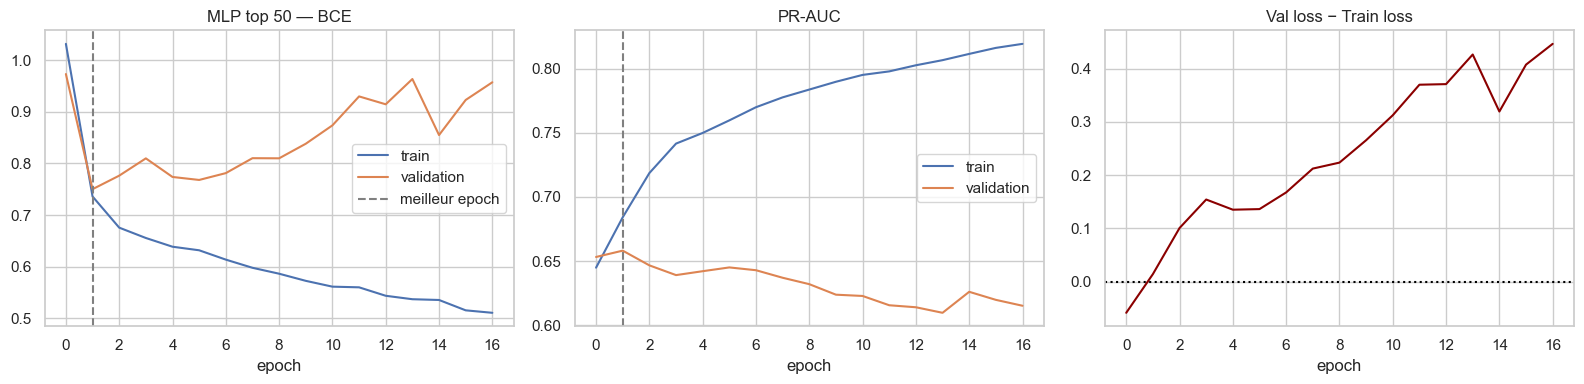

In [48]:
mlp_top = nn.Sequential(
    nn.Linear(len(top_features), 64),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(64, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)

criterion_top = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer_top = torch.optim.AdamW(mlp_top.parameters(), lr=0.001, weight_decay=1e-4)

history_top, best_epoch_top = train_mlp(
    mlp_top, train_loader_top, criterion_top, optimizer_top,
    X_train_top, X_val_top, y_train, y_val,
)

plot_history(history_top, best_epoch_top, "MLP top 50")


#### 7.11.3 Évaluation du MLP filtré

In [49]:
mlp_top_eval = TorchProba(mlp_top)

# validation
res_val_top = evaluate("MLP top-50 — validation", mlp_top_eval, X_val_top, y_val)

# seuil choisi sur la validation
best_thr_top = best_f1_threshold(mlp_top_eval, X_val_top, y_val)
print(f"seuil optimal (F1 validation) : {best_thr_top:.3f}")

# test
res_test_top = evaluate(
    "MLP top-50 — test", mlp_top_eval, X_test_top, y_test, threshold=best_thr_top
)



=== MLP top-50 — validation (seuil = 0.500) ===
Accuracy          : 0.874
Balanced accuracy : 0.772
Precision         : 0.467
Recall            : 0.640
F1                : 0.540
ROC-AUC           : 0.837
PR-AUC            : 0.658
           Prédit 0  Prédit 1
Observé 0       615        65
Observé 1        32        57
seuil optimal (F1 validation) : 0.667

=== MLP top-50 — test (seuil = 0.667) ===
Accuracy          : 0.921
Balanced accuracy : 0.779
Precision         : 0.652
Recall            : 0.597
F1                : 0.623
ROC-AUC           : 0.849
PR-AUC            : 0.635
           Prédit 0  Prédit 1
Observé 0       561        23
Observé 1        29        43


### 7.12 Récapitulatif pour l'antibiotique choisi

Tous les modèles sont réévalués sur le test avec leur seuil choisi sur la validation.


In [50]:
recap_rows = []

for name, model, X_val_m, X_test_m in [
    ("XGBoost", model_xgb, X_val, X_test),
    ("LogReg L1", best_pipe, X_val, X_test),
    ("MLP (toutes features)", mlp_eval, X_val, X_test),
    ("MLP (top 50)", mlp_top_eval, X_val_top, X_test_top),
]:
    thr = best_f1_threshold(model, X_val_m, y_val)
    proba = model.predict_proba(X_test_m)[:, 1]
    pred = (proba >= thr).astype(int)

    recap_rows.append({
        "modèle": name,
        "seuil": round(thr, 3),
        "accuracy": accuracy_score(y_test, pred),
        "balanced_acc": balanced_accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
    })

recap = pd.DataFrame(recap_rows).set_index("modèle").round(4)
print(f"Antibiotique : {ATB}")
recap


Antibiotique : cefuroxime


,seuil,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
modèle,,,,,,,,
XGBoost,0.173,0.9268,0.7580,0.7222,0.5417,0.6190,0.8314,0.6645
LogReg L1,0.330,0.9405,0.7718,0.8511,0.5556,0.6723,0.8362,0.6538
MLP (toutes features),0.937,0.9329,0.7188,0.8889,0.4444,0.5926,0.8253,0.6226
MLP (top 50),0.667,0.9207,0.7789,0.6515,0.5972,0.6232,0.8489,0.6346
